# 05 — Directional escape: where the threat is decides where the fly goes

Phase 4 gave the brain a body, but a simple one to talk to: every LPLC2 (or LC4) neuron on one
side got the **same** input rate, and both sides of the body got the **same** command. That is
enough for "something is coming, back up", not for "something is coming *from the left*".

A real fly knows where the threat is. Flies jump backwards from a threat in front, forwards from
one behind, and somewhere in between from one at the side (Card & Dickinson 2008). Dombrovski et
al. (2023) found part of the wiring for this: LC4 neurons that look forward make more synapses onto
DNp02 (backward escape), LC4 neurons that look back make more onto DNp11 (forward escape). Location
on the eye becomes a choice of motor program through *how many synapses* each neuron makes.

This notebook adds the two missing pieces and tests both:

```
compound eye ─► each LPLC2 / LC4 neuron sees ITS OWN patch ─► spiking brain ─► left vs right escape DNs
                (receptive fields from the connectome)                          │
                                                       steering decoder ◄───────┘ ─► turn away
```

Plan:
1. **Receptive fields from wiring.** Which part of the eye does each of the 314 LPLC2/LC4 neurons see?
2. **The connectome check.** Are Dombrovski et al.'s synaptic gradients in FlyWire, with *our* receptive fields?
3. **A retinotopic encoder.** flygym's eye geometry, receptive-field widths, population coding.
4. **The brain alone.** Replay what a standing fly sees into the brain: does the DN mix change with azimuth?
5. **Steering.** System identification of the walking controller, then a decoder that turns.
6. **Closed loop.** Balls from 0, ±45, ±90°; uniform vs retinotopic input; a GIF.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from c2c.analysis import graph_stats as gs
from c2c.analysis import phase5 as p5
from c2c.data import eyemap as em
from c2c.paths import FIGURES

gs.apply_style()
FIGURES.mkdir(parents=True, exist_ok=True)
pd.set_option("display.width", 160)
from importlib.metadata import version

print("flygym", version("flygym"), "| variant", p5.VARIANT, "| cache", p5.CACHE)

flygym 2.1.1 | variant shiu_min5 | cache /home/claude/connectome-control/data/processed/phase5


## 1. Receptive fields from wiring

A **receptive field** (RF) is the part of the world a neuron responds to. For a visual neuron,
a patch of the eye. Electrophysiologists measure it by moving a stimulus around and watching the
neuron; we have no electrodes, but we have every synapse.

The trick is that the optic lobe is built from **columns**. Behind each of the ~800 ommatidia of
an eye sits the same set of columnar cells (L1–L5, Mi1, Tm2, T4, T5, …), so a columnar cell's
column tells you exactly where in the world it looks. LPLC2 and LC4 are *not* columnar: each one
collects input from a patch of columns. **That patch is its RF**, and the connectome says which
columns are in it.

Three data sets make the chain from synapses to degrees (`c2c/data/eyemap.py`):

| step | data | what it gives |
|---|---|---|
| columns | Matsliah et al. 2024 (FlyWire, right optic lobe) | 22,684 columnar cells → 796 columns with hex coordinates (p, q) |
| eye map | Zhao et al. 2025 (micro-CT of a whole head) | each hex site → the unit vector its ommatidium looks along |
| wiring | Shiu et al. 2024 table (FlyWire v783, every synapse) | which columnar cells feed each LPLC2 / LC4 neuron |

**A. One eye map for FlyWire.** The eye map was measured on a different fly, on the hex grid of a
different connectome (the male CNS). Both grids use the same convention (x = p − q runs front to
back, y = p + q runs bottom to top), so we search for the lattice shift that lands the most FlyWire
columns on eye-map columns:

best shift (dx, dy) = (2, 38): 794 of 796 FlyWire columns land on eye-map sites


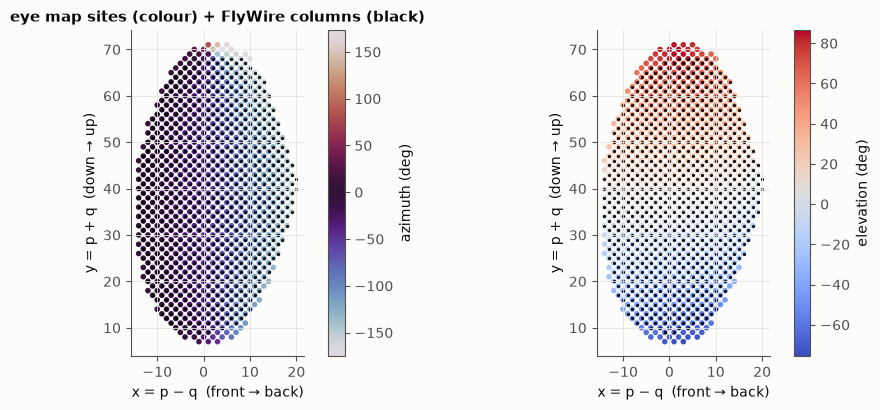

In [2]:
cols, eye = em.load_columns(), em.load_eyemap()
dx, dy, n = em.register_grid(cols, eye)
print(f"best shift (dx, dy) = ({dx}, {dy}): {n} of {cols.column_id.nunique()} FlyWire columns land on eye-map sites")

fig, ax = plt.subplots(1, 2, figsize=(10, 4.2))
fx, fy = em.lattice_xy(*cols.groupby("column_id")[["p", "q"]].first().to_numpy().T)
ex, ey = em.lattice_xy(eye.p, eye.q)
az, el = em.az_el(eye[["x", "y", "z"]].to_numpy())
for a, c, lab in [(ax[0], az, "azimuth (deg)"), (ax[1], el, "elevation (deg)")]:
    sc = a.scatter(ex, ey, c=c, s=9, cmap="twilight" if a is ax[0] else "coolwarm")
    a.scatter(fx + dx, fy + dy, s=1.5, c="k")
    a.set(aspect="equal", xlabel="x = p − q  (front → back)", ylabel="y = p + q  (down → up)")
    plt.colorbar(sc, ax=a, label=lab)
ax[0].set_title("eye map sites (colour) + FlyWire columns (black)")
plt.tight_layout()

**794 of 796 FlyWire columns land on an eye-map site** with a single shift. Two flies, two
connectomes, and the grids agree almost everywhere (the 2 misses take the nearest site). The
orientation was checked against anatomy, not assumed: lamina cell bodies (L1–L5) move posterior as
x grows (r = 0.97) and up as y grows (|r| = 1.00). Assumption E1: after the shift, a FlyWire column
looks where the eye-map column at the same place looks. Two flies differ by a column or two (~5°),
small next to receptive fields of 30–60°.

**B. The left side.** Columns were only assigned on the right. For the left optic lobe we use
symmetry: reflect each left columnar cell body into the right lobe and give it the direction of
its 3 nearest right cells of the same type (then mirror that direction into the left eye). The
reflection is fitted, not assumed: iterative closest point with an orthogonal Procrustes step,
so left T4s land on right T4s, Mi1s on Mi1s.

How good is a cell body as a handle on a column? Test it where the answer is known: do the same
nearest-neighbour trick on the *right* side and compare with the true columns.

In [3]:
rf, diag = p5.receptive_field_table()
val = p5.mirror_validation()
pd.Series({**diag, **val}).round(2)

columns_on_map                  794.00
columns                         796.00
mirror_residual_um                5.09
mirror_det                       -1.01
right_cells                   22684.00
left_cells                    20976.00
cell_error_deg_median             6.09
rf_centre_error_deg_median        1.23
rf_centre_error_deg_max          14.97
sigma_true_mean                   9.63
sigma_estimated_mean             11.58
dtype: float64

* The fitted map is a reflection (det = −1.01, scale ≈ 1). A mirrored left cell body lands
  5.1 µm from the nearest right cell of its type, about one cell spacing (4.9 µm). Assumption E2:
  the two optic lobes are mirror images.
* A single cell body is a noisy handle: its estimated direction is off by **6.1°** (about one
  column) on the right side, where we can check.
* But a receptive field averages hundreds of inputs, so the noise mostly cancels: RF centres
  come out within **1.2°** (median) of the true ones. The cost is width: noise widens the RF
  (σ 11.6° vs 9.6°). That is why the left-side σ below is ~20% larger than the right: an
  artefact of the method, not biology.

**C. Receptive fields.** For neuron *n* with synapse counts $s_j$ from mapped columnar cells that look
along unit vectors $d_j$:

$$u_n = \frac{\sum_j s_j d_j}{\lVert \sum_j s_j d_j \rVert}, \qquad
\sigma_n = \sqrt{\frac{\sum_j s_j\, \angle(d_j, u_n)^2}{2 \sum_j s_j}}$$

$u_n$ is where the input comes from on average (the RF centre), $\sigma_n$ its spread, written as the
per-axis standard deviation of a 2-D Gaussian.

az    el  sigma  frac_mapped  syn_mapped
cell_type side                                             
LC4       left   66.1  16.0   12.5          0.5       547.0
          right -60.7  10.6    9.4          0.4       596.0
LPLC2     left   64.6   9.5   11.2          0.3       234.0
          right -61.7   9.6    9.7          0.4       357.5

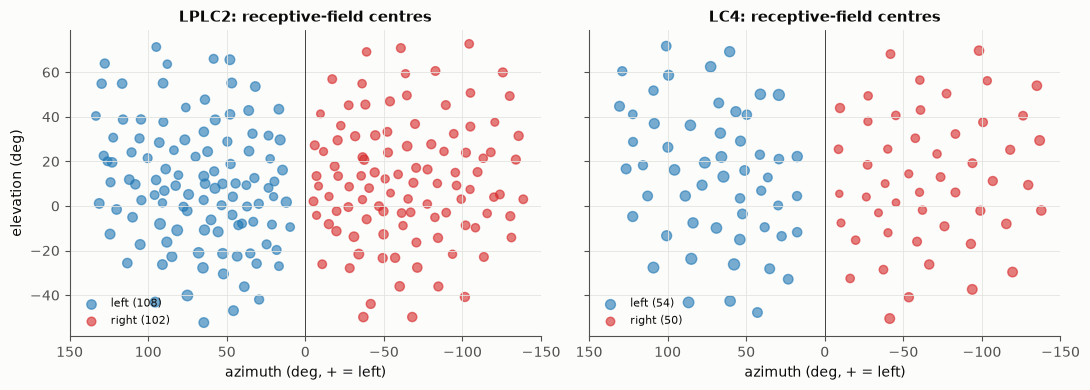

In [4]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
for a, t in zip(ax, ["LPLC2", "LC4"]):
    for side, c in [("left", "C0"), ("right", "C3")]:
        d = rf[(rf.cell_type == t) & (rf.side == side)]
        a.scatter(d.az, d.el, s=4 * d.sigma, c=c, alpha=0.6, label=f"{side} ({len(d)})")
    a.axvline(0, color="k", lw=0.5)
    a.set(title=f"{t}: receptive-field centres", xlabel="azimuth (deg, + = left)", xlim=(150, -150))
    a.legend(frameon=False, fontsize=8)
ax[0].set_ylabel("elevation (deg)")
plt.tight_layout()
plt.savefig(FIGURES / "phase5_receptive_fields.png", dpi=150)
rf.groupby(["cell_type", "side"])[["az", "el", "sigma", "frac_mapped", "syn_mapped"]].median().round(1)

The 314 RF centres tile each eye, from about 10° to 140° azimuth and −50° to +70° elevation,
left neurons on the left eye, right on the right (no neuron was told which side it sees: that comes
out of the wiring). Two things to keep in mind:

* **Only 30–50% of each neuron's input synapses are from mapped columnar cells.** The rest come
  from non-columnar neurons (other LPLC2s, Y3, LPi cells…) that have no single direction. The RF
  is built from the part of the input that does.
* **σ ≈ 10° is narrower than LPLC2's measured RF** (~60° across, Klapoetke et al. 2017). The
  direct inputs (T4, T5, Tm cells) each pool several columns themselves, so the connectome gives
  centres and *relative* sizes, and physiology gives the absolute width (section 3).

## 2. The connectome check: Dombrovski et al. 2023

The prediction, with directions taken from behaviour (front threat → backward jump):
* LC4 → **DNp02** (backward escape) should *decrease* from front to back of the eye,
* LC4 → **DNp11** (forward escape) should *increase* from front to back,
* LPLC2 → **giant fiber** should increase from ventral to dorsal (their follow-up, 2025).

We count every synapse from each LC neuron onto each escape DN (no threshold) and regress against
the neuron's RF position. Both eyes are folded together with |azimuth| (0° = front, 90° = side).

In [5]:
grid = p5.lc_dn_synapses()
print(p5.ipsi_fraction(grid).round(2))
fits = pd.DataFrame([p5.gradient(grid, ct, dn, ax)
                     for ct, dn, ax in [("LC4", "DNp02", "az_abs"), ("LC4", "DNp11", "az_abs"),
                                        ("LC4", "DNp01", "az_abs"), ("LC4", "DNp04", "az_abs"),
                                        ("LPLC2", "DNp01", "el"), ("LPLC2", "DNp04", "az_abs"),
                                        ("LC4", "DNp04", "el")]])
fits.round(3)

ipsi             contra_syn  ipsi_syn  ipsi_fraction
cell_type dn                                        
LC4       DNp01           0       805            1.0
          DNp02           0      1001            1.0
          DNp04           0      1854            1.0
          DNp11           0       923            1.0
LPLC2     DNp01           0      1080            1.0
          DNp02           0         5            1.0
          DNp04           0      1212            1.0
          DNp11           0        19            1.0


,cell_type,dn,axis,slope_per_10deg,r,p,n,mean_syn
0,LC4,DNp02,az_abs,-0.698,-0.514,0.000,104,9.625
1,LC4,DNp11,az_abs,1.909,0.792,0.000,104,8.875
2,LC4,DNp01,az_abs,-0.234,-0.261,0.007,104,7.740
3,LC4,DNp04,az_abs,-0.010,-0.004,0.967,104,17.827
4,LPLC2,DNp01,el,0.783,0.550,0.000,210,5.143
5,LPLC2,DNp04,az_abs,-0.665,-0.580,0.000,210,5.771
6,LC4,DNp04,el,-1.972,-0.682,0.000,104,17.827


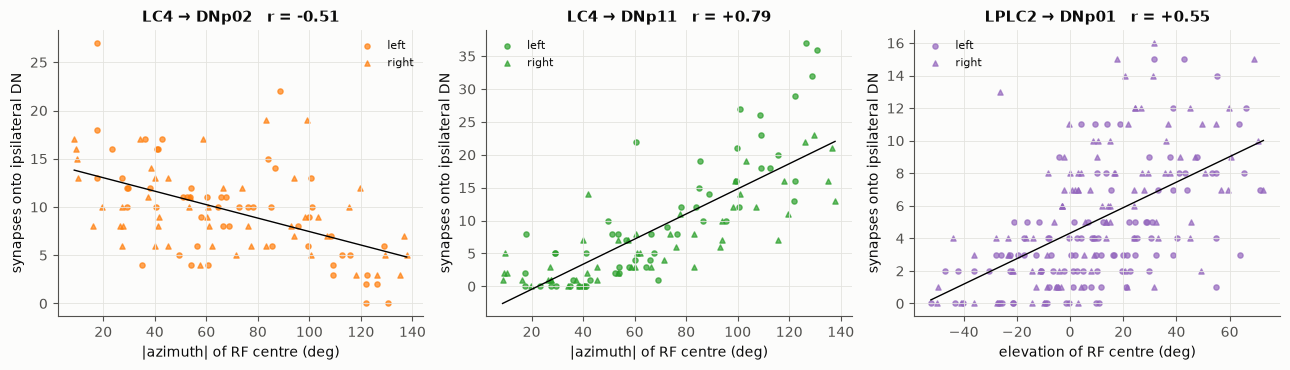

In [6]:
fig, ax = plt.subplots(1, 3, figsize=(13, 3.8))
panels = [("LC4", "DNp02", "az_abs", "C1"), ("LC4", "DNp11", "az_abs", "C2"), ("LPLC2", "DNp01", "el", "C4")]
for a, (ct, dn, axis, c) in zip(ax, panels):
    g = grid[(grid.cell_type == ct) & (grid.dn == dn) & grid.ipsi]
    g = g.groupby("root_id").agg(syn=("syn", "sum"), x=(axis, "first"), side=("side", "first"))
    for side, m in [("left", "o"), ("right", "^")]:
        d = g[g.side == side]
        a.scatter(d.x, d.syn, s=14, marker=m, color=c, alpha=0.7, label=side)
    f = p5.gradient(grid, ct, dn, axis)
    xs = np.linspace(g.x.min(), g.x.max(), 2)
    a.plot(xs, g.syn.mean() + f["slope_per_10deg"] / 10 * (xs - g.x.mean()), "k-", lw=1)
    a.set(title=f"{ct} → {dn}   r = {f['r']:+.2f}",
          xlabel="|azimuth| of RF centre (deg)" if axis == "az_abs" else "elevation of RF centre (deg)",
          ylabel="synapses onto ipsilateral DN")
    a.legend(frameon=False, fontsize=8)
plt.tight_layout()
plt.savefig(FIGURES / "phase5_dombrovski_gradients.png", dpi=150)

**All three predicted gradients are in FlyWire, with receptive fields derived independently of
the papers:**

* LC4 → DNp11 increases from front to back (r = +0.79, from ~0 synapses for forward-looking LC4
  to 20–37 for rear-looking ones), the strongest of the three.
* LC4 → DNp02 runs the opposite way (r = −0.51).
* LPLC2 → giant fiber increases from ventral to dorsal (r = +0.55).
* Every LC4/LPLC2 synapse onto these DNs is **ipsilateral** (contra = 0), which is what lets the
  decoder read "which side" from "which side's DNs" (assumption S1 below).

Two gradients I was not looking for: LC4 → DNp04 has no front-to-back gradient but a strong
up-down one (r = −0.68, ventral-looking LC4 make more synapses), and LPLC2 → DNp04 is front-heavy
(r = −0.58). I did not find these in the papers I read; treat them as observations of this
analysis, not established results.

## 3. A retinotopic encoder

**The eye in flygym.** To ask "does this ommatidium fall in that neuron's RF" we need every
ommatidium's viewing direction. flygym renders each eye with a pinhole camera, warps the image with a
fisheye lookup table and averages the pixels inside each hexagon. Running that chain backwards
(corrected pixel → raw pixel → ray through the pinhole → world) gives each ommatidium's direction
(`FlyArena.ommatidia_directions`; a test renders a small ball along computed directions and checks
the dark patch lands within 3°).

In [7]:
omm = p5.ommatidia_dirs()
for e, name in enumerate(["left", "right"]):
    a, b = em.az_el(omm[e])
    print(f"{name} eye: azimuth {a.min():6.1f} … {a.max():6.1f} deg, elevation {b.min():5.1f} … {b.max():5.1f} deg")
scale = p5.sigma_scale(rf)
print(f"\nsigma_scale = {scale:.2f}: median LPLC2 sigma {rf[rf.cell_type=='LPLC2'].sigma.median():.1f} deg "
      f"-> functional sigma {scale * rf[rf.cell_type=='LPLC2'].sigma.median():.1f} deg "
      f"= {p5.LPLC2_RF_FWHM:.0f} deg full width at half maximum")

left eye: azimuth  -11.4 …  138.1 deg, elevation -73.4 …  73.5 deg
right eye: azimuth -137.6 …   12.0 deg, elevation -73.3 …  73.6 deg

sigma_scale = 2.48: median LPLC2 sigma 10.3 deg -> functional sigma 25.5 deg = 60 deg full width at half maximum


Each flygym eye sees from about −11° to 138° azimuth, so the two eyes overlap by ~23° in front.
With σ scaled by 2.48 (assumption R3), the median LPLC2 RF is 60° across at half maximum, the
measured value; every neuron keeps its connectome centre and its width relative to the others.

**The encoder** (`RetinotopicEncoder` in `c2c/control/encoder.py`). Same looming features as
Phase 4 (WHAT: angular size for LPLC2, expansion speed for LC4), times a spatial factor (WHERE):

$$r_i = f_{\text{type}}(\theta, \dot\theta) \cdot h_i, \qquad h_i = \max_j \left( w_{ij}\, c_j \right),
\qquad w_{ij} = \exp\!\left(-\frac{\angle(u_i, d_j)^2}{2\sigma_i^2}\right)$$

$c_j$ is how dark ommatidium *j* is. $h_i$ asks how close to neuron *i*'s RF centre the object
reaches: 1 if it covers the centre, a Gaussian tuning curve for a small object off-centre, 0 if
nothing dark is in view. Because $h_i \le 1$, no neuron ever gets more than its Phase 4 rate, and
if every RF centre is covered the encoder *is* the Phase 4 encoder (a test checks exactly that).

**Population coding.** One neuron's rate cannot tell "small object at my centre" from "big object
off to the side". The position is in the *pattern* across the population. Below, a standing fly,
ball from five directions; each dot is one neuron at its RF centre, coloured by its mean drive while
the ball approaches.

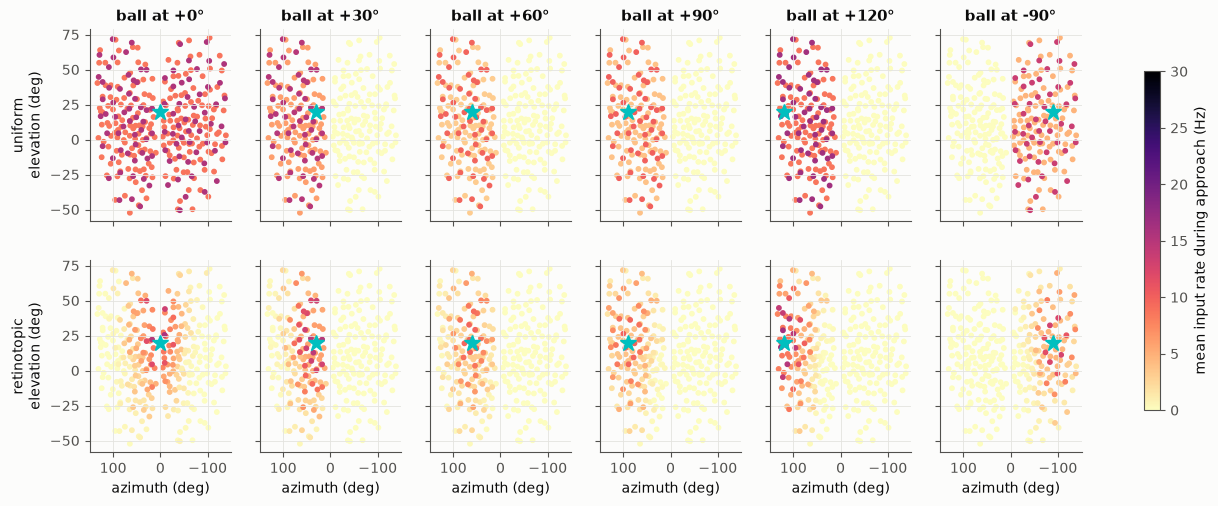

In [8]:
from c2c.analysis.phase3 import network
from c2c.control.encoder import looming_drive

record = p5.record_drive()
net = network(p5.VARIANT)
drive_idx, groups = looming_drive(net.aligned)
info = rf.set_index("root_id").loc[net.g.root_ids[drive_idx]]

azs = [0, 30, 60, 90, 120, -90]
fig, ax = plt.subplots(2, len(azs), figsize=(16, 5.5), sharex=True, sharey=True)
for col, az in enumerate(azs):
    for row, enc in enumerate(p5.ENCODERS):
        d = np.asarray(record[(enc, az)]["drive"])
        m = d[d.sum(1) > 0].mean(0) if (d.sum(1) > 0).any() else d.mean(0)
        a = ax[row, col]
        sc = a.scatter(info.az, info.el, c=m, s=10, cmap="magma_r", vmin=0, vmax=30)
        a.plot([az], [20], "c*", ms=12)
        a.set(xlim=(150, -150))
        if row == 0:
            a.set_title(f"ball at {az:+d}°")
    ax[0, 0].set_ylabel("uniform\nelevation (deg)")
    ax[1, 0].set_ylabel("retinotopic\nelevation (deg)")
for a in ax[1]:
    a.set_xlabel("azimuth (deg)")
fig.colorbar(sc, ax=ax, label="mean input rate during approach (Hz)", shrink=0.8)
plt.savefig(FIGURES / "phase5_population_code.png", dpi=150, bbox_inches="tight")

Top row (uniform, Phase 4): the whole eye on the ball's side lights up the same, wherever the
ball is. A ball at 30° and one at 120° look identical to the brain. Bottom row (retinotopic): a
**patch** of neurons around the ball lights up, and it moves with the ball. Same object, same
features, different neurons: that is a population code. Note the price: most neurons now see
the ball off-centre, so each gets less drive than in Phase 4.

## 4. The brain alone: does the escape mix follow the ball?

Before adding steering and feedback, a clean test of the gradients' *function*: take the input
recorded from the standing fly for each azimuth and replay it into the brain alone, 10 independent
Poisson trials at once (the stepper is batched over trials). No body, no feedback, nothing else
changes between conditions except where the ball was.

In [9]:
rep = p5.replay_table(record)
mean = rep.groupby(["encoder", "azimuth", "dn", "dn_side"])["spikes"].mean().unstack(["dn", "dn_side"])
mean.round(1)

dn                  DNp01       DNp02      DNp04       DNp11     
dn_side                 L     R     L    R     L     R     L    R
encoder     azimuth                                              
retinotopic -90       1.1   2.0   0.0  1.5   0.0   4.3   0.0  2.3
             0        1.5   3.7   2.3  0.8   7.2   4.3   0.0  0.0
             30       1.9   1.5   3.7  0.0   8.3   0.0   0.9  0.0
             60       1.6   0.8   2.7  0.0   6.4   0.0   1.9  0.0
             90       1.7   0.2   2.5  0.0   7.1   0.0   4.1  0.0
             120      1.9   0.3   2.0  0.0   9.0   0.0   6.3  0.0
uniform     -90       2.6   6.7   0.0  4.8   0.0   9.5   0.0  4.0
             0        9.7  12.5   8.2  6.6  17.3  14.3   8.2  3.4
             30       6.5   4.5   6.3  0.0  13.1   0.0   6.7  0.0
             60       4.0   2.6   4.7  0.0   9.6   0.0   5.0  0.0
             90       5.3   3.2   5.2  0.0  11.1   0.0   5.7  0.0
             120      8.0   6.5   8.3  0.0  17.4   0.0   8.3  0.0

mean   sem
encoder     azimuth            
retinotopic 0        0.00  0.00
            30       0.20  0.02
            60       0.41  0.03
            90       0.62  0.02
            120      0.76  0.02
uniform     0        0.50  0.01
            30       0.52  0.01
            60       0.52  0.01
            90       0.52  0.01
            120      0.50  0.01

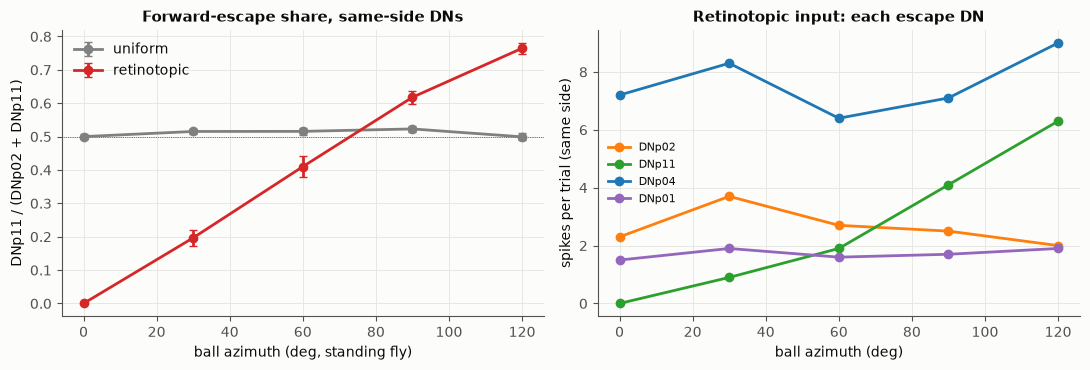

In [10]:
ipsi = rep.assign(ipsi=np.where(rep.azimuth >= 0, rep.dn_side == "L", rep.dn_side == "R"))
ipsi = ipsi[ipsi.ipsi & (rep.azimuth >= 0)]
tot = ipsi.groupby(["encoder", "azimuth", "trial", "dn"])["spikes"].sum().unstack("dn")
tot["DNp11 share"] = tot["DNp11"] / (tot["DNp11"] + tot["DNp02"]).replace(0, np.nan)
share = tot.groupby(["encoder", "azimuth"])["DNp11 share"].agg(["mean", "sem"])

fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
for enc, c in [("uniform", "0.5"), ("retinotopic", "C3")]:
    s = share.loc[enc]
    ax[0].errorbar(s.index, s["mean"], yerr=s["sem"], color=c, marker="o", capsize=3, label=enc)
    g = tot.loc[enc].groupby("azimuth")[["DNp02", "DNp11", "DNp04", "DNp01"]].mean()
    if enc == "retinotopic":
        for dn, cc in [("DNp02", "C1"), ("DNp11", "C2"), ("DNp04", "C0"), ("DNp01", "C4")]:
            ax[1].plot(g.index, g[dn], marker="o", color=cc, label=dn)
ax[0].set(xlabel="ball azimuth (deg, standing fly)", ylabel="DNp11 / (DNp02 + DNp11)",
          title="Forward-escape share, same-side DNs")
ax[0].axhline(0.5, color="k", lw=0.5, ls=":")
ax[0].legend(frameon=False)
ax[1].set(xlabel="ball azimuth (deg)", ylabel="spikes per trial (same side)",
          title="Retinotopic input: each escape DN")
ax[1].legend(frameon=False, fontsize=8)
plt.tight_layout()
plt.savefig(FIGURES / "phase5_brain_replay.png", dpi=150)
share.round(2)

**This is the Dombrovski prediction working, not just present.** With retinotopic input, the
forward-escape share of the same-side escape DNs rises steadily with azimuth: **0.00 for a ball
straight ahead, 0.20 at 30°, 0.41 at 60°, 0.62 at 90°, 0.76 at 120°**. A frontal ball gets zero
DNp11 spikes (a pure backward program); a ball from behind gets mostly DNp11. That is the behaviour
Card & Dickinson measured (front → jump back, behind → jump forward), falling out of synapse
counts.

With uniform input the share is flat at 0.50 for every direction. The gradients are still in
the wiring, but the encoder has averaged away the information they are built to use: when every
LC4 on a side gets the same rate, it no longer matters which of them makes more synapses onto
DNp11. **An encoder can erase exactly the information the downstream wiring needs.** That is a
design lesson that has nothing to do with flies.

Also visible: DNp11 does almost all the changing (0 → 6.3 spikes per trial) while DNp02 stays
around 2–4, matching its weaker gradient (r = −0.51 vs +0.79), and retinotopic input drives about
half as many DN spikes as uniform.

## 5. Steering

### System identification of the walking controller

flygym's `HybridTurningController` takes two numbers, one per side of the body. Before writing a
decoder that turns, measure what the body does with asymmetric commands, the way you would
characterise a motor before closing a loop around it: command $(s_L, s_R) = (v + w, v - w)$, let
the gait settle for 200 ms, measure yaw rate and speed over the next 800 ms.

v,-1.0,-0.5,0.5,1.0
w,,,,
-0.6,24.0,-6.0,234.0,160.0
-0.4,23.0,17.0,163.0,116.0
-0.2,20.0,16.0,83.0,70.0
0.0,3.0,-4.0,-2.0,3.0
0.2,-23.0,-20.0,-76.0,-64.0
0.4,-24.0,-20.0,-162.0,-113.0
0.6,-27.0,-100.0,-301.0,-159.0


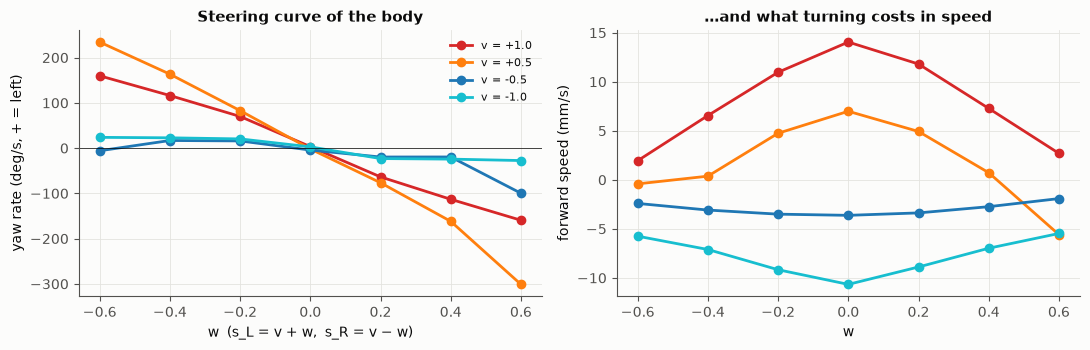

In [11]:
cal = p5.steering_calibration()
fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
for v, c in zip(sorted(cal.v.unique(), reverse=True), ["C3", "C1", "C0", "C9"]):
    d = cal[cal.v == v]
    ax[0].plot(d.w, d.yaw_rate_deg_s, "o-", color=c, label=f"v = {v:+.1f}")
    ax[1].plot(d.w, d.speed_mm_s, "o-", color=c, label=f"v = {v:+.1f}")
ax[0].axhline(0, color="k", lw=0.5)
ax[0].set(xlabel="w  (s_L = v + w,  s_R = v − w)", ylabel="yaw rate (deg/s, + = left)",
          title="Steering curve of the body")
ax[1].set(xlabel="w", ylabel="forward speed (mm/s)", title="…and what turning costs in speed")
ax[0].legend(frameon=False, fontsize=8)
plt.tight_layout()
plt.savefig(FIGURES / "phase5_steering_calibration.png", dpi=150)
cal.pivot(index="w", columns="v", values="yaw_rate_deg_s").round(0)

* **Walking forward (v = 1), the body steers like a differential-drive robot:** yaw rate is close to
  linear in w, about 265°/s per unit, and turning costs speed (14 mm/s straight, 2–3 mm/s at
  |w| = 0.6). Left legs harder than right (w > 0) turns the fly right, as the decoder assumes.
* **Backing up (v = −1), it can barely steer:** ±20–27°/s at most, with the same sign. The
  backward gait has about a sixth of the steering authority (27 vs 160°/s at |w| = 0.6).

So a fly that is backing away from a threat cannot turn much until its command goes forward again.
Keep that in mind when reading the closed-loop results.

### The steering decoder

`SteeringDecoder` (in `c2c/control/decoder.py`) is a differential-drive mixer, the same split a
mobile robot uses: a translational command $v$ (exactly Phase 4's decoder, A1–A6) and a turning
command $w$:

$$s_L = v + w, \quad s_R = v - w, \qquad w = k_\text{turn}\,\frac{D_L - D_R}{1 + D_L + D_R}$$

$D_\text{side}$ = (summed backward + forward escape DN rate on that side) / r50. Assumptions:

| | assumption | basis |
|---|---|---|
| S1 | each side's escape DNs report a threat on that side | LC → DN synapses are 100% ipsilateral (section 2) |
| S2 | flies escape **away** from a threat; on foot, more drive on the left → turn right | Card & Dickinson 2008 (jump direction vs threat azimuth) |
| S3 | same competition rule as A6: no escape activity → w = 0; one side only → \|w\| → k_turn | keeps \|s\| ≤ 1.2, the controller's stable range |
| — | k_turn = 0.6 | full asymmetry → ~160°/s while walking (calibration above) |

What this does not claim: that DNp02/DNp04/DNp11 steer the real fly. The identified walking steering
neurons are others (DNa02 turns the fly *towards* its own side; Rayshubskiy et al., eLife). This is a
functional map from "where is the threat" to "turn away", using the left/right signal where the
model brain carries it.

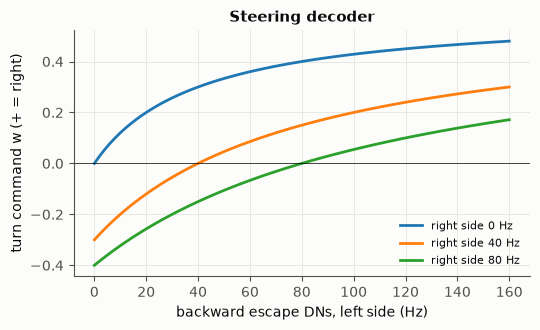

In [12]:
from c2c.control.decoder import SteeringDecoder

names = [f"{t} {s}" for t in ["DNp01", "DNp04", "DNp02", "DNp11"] for s in "LR"]
dec = SteeringDecoder(names)
left = np.linspace(0, 160, 81)
fig, ax = plt.subplots(figsize=(5.5, 3.4))
for right in [0, 40, 80]:
    w = [dec.turn(np.array([0, 0, l / 2, right / 2, l / 2, right / 2, 0, 0], float)) for l in left]
    ax.plot(left, w, label=f"right side {right} Hz")
ax.axhline(0, color="k", lw=0.5)
ax.set(xlabel="backward escape DNs, left side (Hz)", ylabel="turn command w (+ = right)",
       title="Steering decoder")
ax.legend(frameon=False, fontsize=8)
plt.tight_layout()

## 6. Closed loop: balls from five directions

Same ball as Phase 4 (2 mm radius, 150 mm/s, 20° above the horizon, stops 8 mm short), now from
azimuth 0, ±45 or ±90°, three seeds each, with the **uniform** (Phase 4) and the **retinotopic**
encoder. Both use the steering decoder.

One fix to the stimulus first. The walking controller drifts a little to the left (about 13° of
heading over a second, measured with the brain disconnected). A ball aimed at the fly's *starting*
position would therefore arrive off to one side: in a first version, the "frontal" ball was 13° to
the right by the time the eyes saw it. So the ball now **leads its target**, like a predator: it
flies at where the non-reacting fly's head will be on arrival, from the requested azimuth relative
to where the fly will be heading (`aimed_ball`). `bearing_deg` reports where the ball actually was
at input onset.

In [13]:
runs = p5.experiments()
base = p5.baseline_walk()
tab = p5.summary_table(runs)
cols = ["encoder", "azimuth", "seed", "bearing_deg", "onset_ms", "turn_deg", "escape_dir_deg",
        "backed_up", "away", "DNp02 L", "DNp02 R", "DNp11 L", "DNp11 R", "DNp04 L", "DNp04 R"]
tab[cols].round(1)

,encoder,azimuth,seed,bearing_deg,onset_ms,turn_deg,escape_dir_deg,backed_up,away,DNp02 L,DNp02 R,DNp11 L,DNp11 R,DNp04 L,DNp04 R
0,uniform,0,0,-1.9,368.0,4.2,169.5,True,NaN,5,6,5,3,28,26
1,uniform,0,1,12.9,400.0,-56.6,-42.0,True,True,5,0,4,0,27,0
2,uniform,0,2,26.8,402.0,-53.7,-30.8,True,True,5,0,6,0,27,0
3,retinotopic,0,0,-1.9,368.0,3.0,15.3,True,NaN,1,1,0,0,12,15
4,retinotopic,0,1,12.9,400.0,-51.0,-40.1,True,True,3,0,0,0,19,0
5,retinotopic,0,2,26.8,402.0,-50.0,-24.0,True,True,3,0,1,0,20,0
6,uniform,45,0,35.0,406.0,-60.3,-64.3,True,True,5,0,5,0,32,0
7,uniform,45,1,58.7,418.0,-73.9,-77.8,True,True,7,0,7,0,22,0
8,uniform,45,2,69.5,426.0,-50.8,-58.6,True,True,5,0,3,0,31,0
9,retinotopic,45,0,35.0,406.0,-41.9,-33.8,True,True,3,0,0,0,21,0


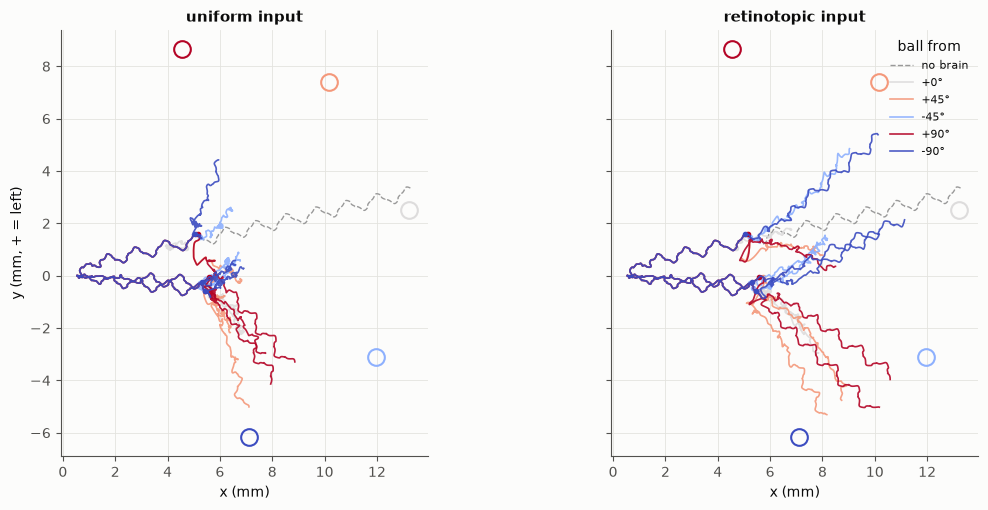

In [14]:
fig, ax = plt.subplots(1, 2, figsize=(12, 5.2), sharey=True)
th = base["thorax"]
for a, enc in zip(ax, p5.ENCODERS):
    a.plot(th[:, 0], th[:, 1], color="0.6", lw=1, ls="--", label="no brain")
    for az in p5.AZIMUTHS:
        c = plt.cm.coolwarm((az + 90) / 180)
        for s, log in enumerate(runs[(enc, az)]):
            p = log["thorax"]
            a.plot(p[:, 0], p[:, 1], color=c, lw=1.2, alpha=0.9, label=f"{az:+d}°" if s == 0 else None)
            k = int(np.argmax(log["lplc2"].sum(1) + log["lc4"].sum(1) > 0))
            a.plot(p[k, 0], p[k, 1], "o", color=c, ms=3)
        b = runs[(enc, az)][0]["ball"][-1]
        a.plot(b[0], b[1], "o", mfc="none", mec=c, ms=12, mew=1.5)
    a.set(aspect="equal", title=f"{enc} input", xlabel="x (mm)")
ax[0].set_ylabel("y (mm, + = left)")
ax[1].legend(frameon=False, fontsize=8, title="ball from")
plt.tight_layout()
plt.savefig(FIGURES / "phase5_trajectories.png", dpi=150)

Grey dashes: brain disconnected, the fly walks on and drifts left. With the brain connected, the
fly reacts in every run and heads off **away from the ball's side**: balls from the left (red)
send it right, balls from the right (blue) send it left. Retinotopic runs travel further in the
first 300 ms after onset (1.9–2.3 mm vs 0.6–1.6 mm for lateral balls): with half the backward
drive, the command returns to forward walking sooner, and forward walking is where the body can
turn.

One caveat on the stimulus. The ball is aimed using the seed-0 baseline walk, but seeds 1 and 2
walk slightly differently, so the nominal "0°" ball actually arrived 13° and 27° to the left for
them. The tables therefore use the **measured bearing at onset**, not the nominal azimuth.

In [15]:
agg = tab.groupby(["encoder", "azimuth"]).agg(
    bearing=("bearing_deg", "mean"), turn=("turn_deg", "mean"), turn_sd=("turn_deg", "std"),
    escape_dir=("escape_dir_deg", "mean"), away=("away", "mean"))
agg.round(1)

bearing  turn  turn_sd  escape_dir away
encoder     azimuth                                         
retinotopic -90        -79.9  28.5      6.7        19.1  1.0
            -45        -32.0  48.6      4.1        22.6  1.0
             0          12.6 -32.6     30.9       -16.3  1.0
             45         54.4 -51.7      8.7       -45.2  1.0
             90         96.0 -33.6      6.2       -35.3  1.0
uniform     -90        -79.9  43.5      5.9        43.2  1.0
            -45        -32.0  50.2      8.2        29.6  1.0
             0          12.6 -35.4     34.3        32.2  1.0
             45         54.4 -61.7     11.6       -66.9  1.0
             90         96.0 -52.1      9.9       -60.4  1.0

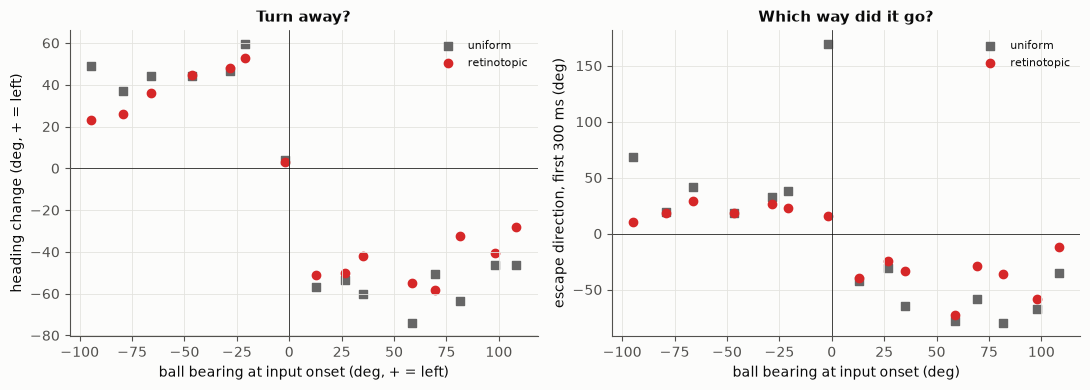

In [16]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
for enc, c, m in [("uniform", "0.4", "s"), ("retinotopic", "C3", "o")]:
    d = tab[tab.encoder == enc]
    ax[0].scatter(d.bearing_deg, d.turn_deg, color=c, marker=m, label=enc)
    ax[1].scatter(d.bearing_deg, d.escape_dir_deg, color=c, marker=m, label=enc)
xs = np.linspace(-100, 100, 3)
ax[0].axhline(0, color="k", lw=0.5)
ax[0].axvline(0, color="k", lw=0.5)
ax[0].set(xlabel="ball bearing at input onset (deg, + = left)", ylabel="heading change (deg, + = left)",
          title="Turn away?")
ax[1].axhline(0, color="k", lw=0.5)
ax[1].axvline(0, color="k", lw=0.5)
ax[1].set(xlabel="ball bearing at input onset (deg)",
          ylabel=f"escape direction, first {p5.ESCAPE_WINDOW:.0f} ms (deg)",
          title="Which way did it go?")
for a in ax:
    a.legend(frameon=False, fontsize=8)
plt.tight_layout()
plt.savefig(FIGURES / "phase5_turn_vs_bearing.png", dpi=150)

**Turning away is robust.** Every run with the ball off-axis turned away from it: 28 of 28 across
both encoders (24 lateral + the 4 "frontal" runs that arrived 13–27° off-centre). The one ball that
really came from straight ahead (seed 0, bearing −1.9°) produced almost no turn (3–4°); the
uniform-input fly backed almost straight away from it (escape direction 170°).

**But turning is not what retinotopy adds.** The uniform encoder already turns the fly, because
Phase 4 scaled each eye's rates by its share of the object, so left vs right was never lost. Uniform
input actually turns the fly *more* (43–62° vs 29–52° on average), because it drives about twice
as many escape-DN spikes. What retinotopy adds is the forward/backward choice of section 4, and in
closed loop that signal is blurred by the body: the backward gait can barely steer, and three seeds
of a walking-only fly are a noisy readout of a jump direction. The clean test of the Dombrovski
prediction is the brain-alone replay; the closed loop shows that the result survives a body and
feedback in the sense that matters (the fly turns away) without proving the finer point.

Despite half the drive, the retinotopic fly keeps a similar distance from the ball (closest gap
4.9–7.0 mm vs 5.1–7.1 mm).

### The GIF: a ball from the left, seen from above

In [17]:
gif_log = p5.gif_run()
s = p5.summary(gif_log, p5.GIF_AZIMUTH)
print({k: round(v, 1) if isinstance(v, float) else v for k, v in s.items()
       if k in ("bearing_deg", "turn_deg", "escape_dir_deg", "backed_up", "away")})

{'turn_deg': -50.8, 'escape_dir_deg': -39.0, 'backed_up': True, 'bearing_deg': 80.5, 'away': True}


![side approach](../results/figures/phase5_side_approach_az+90.gif)

A ball from the left (bearing 80° at onset). Only the **left** escape DNs fire (peaking around
160 Hz in the filtered rate while the right side stays at 0), so the left legs step harder than
the right: the decoder turns the fly right. It turns about 51°, backs up briefly, then walks off
forward-right, away from the ball. Played at 1/10 speed, seen from above.

## Takeaways

1. **Receptive fields from wiring.** Every one of the 314 LPLC2/LC4 neurons gets an RF from its
   synapses, a column map and an eye map, no physiology except one width. Checked where possible:
   RF centres within 1.2° of truth on the side where columns are known.
2. **The Dombrovski et al. 2023 gradients are in FlyWire** with our independently derived RFs
   (LC4 → DNp11 r = +0.79, LC4 → DNp02 r = −0.51, LPLC2 → giant fiber r = +0.55), plus two DNp04
   gradients I was not looking for.
3. **They do what was predicted, but only with retinotopic input.** Replayed into the brain alone,
   the forward-escape share goes from 0.00 (ball ahead) to 0.76 (ball behind). With uniform input
   it is flat at 0.50: the encoder threw the information away.
4. **The fly turns away from side threats** in 28 of 28 off-axis runs, with a 2-number steering
   mixer and one gain. Left/right was enough for that; retinotopy costs half the escape drive and
   gives gentler turns.
5. **The body sets limits the brain can't fix.** The backward gait has about a sixth of the steering
   authority, so a fly backing away can't also turn. Directional escape on foot is a weaker test
   than the takeoffs it stands in for.

**Assumptions to remember** (each stated where it is used): E1–E3 (eye map and RFs), R1–R3
(separable RF, head frame, physiological width), S1–S3 (steering). Biggest simplifications: no
motion detectors inside the RF, the left side by symmetry, and a functional steering map rather
than the fly's own steering neurons.